In [1]:
pip -q install langgraph langchain langchain-core langchain-groq groq

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import getpass

if not os.environ.get("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass.getpass("Digite sua GROQ_API_KEY: ")
print("✅ GROQ_API_KEY configurada!")

✅ GROQ_API_KEY configurada!


In [2]:
from typing import TypedDict, Literal

from groq import Groq

from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage

from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

In [3]:
def make_llm(temperature: float = 0.7) -> ChatGroq:
    return ChatGroq(
        model="openai/gpt-oss-120b",
        temperature=temperature,
    )

llm = make_llm()
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000190916DF920>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000019092E54BF0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

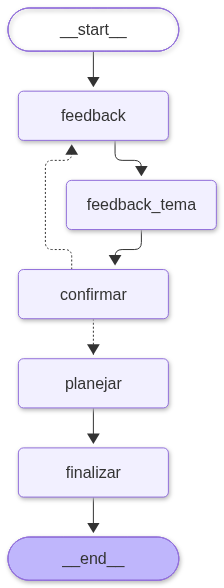

In [4]:
from typing import TypedDict, Literal

from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command


class FeedbackState(TypedDict, total=False):
    tema: str
    nivel: str
    roteiro: str
    versao_final: str

def node_pedir_feedback(state: FeedbackState) -> FeedbackState:
    resposta = interrupt({
        "pergunta": (
            "Qual nível deseja? iniciante/intermediário/avançado. "
            "Deixe em branco para manter."
        ),
        "nivel_atual": state.get("nivel", "iniciante"),
    })

    if isinstance(resposta, str) and resposta.strip():
        return {"nivel": resposta.strip()}

    return {}


def node_feedback_tema(state: FeedbackState) -> FeedbackState:
    resposta = interrupt({
        "pergunta": "Deseja mudar de tema? Deixe em branco para manter.",
        "tema_atual": state.get("tema", ""),
    })

    if isinstance(resposta, str) and resposta.strip():
        return {"tema": resposta.strip()}

    return {}
    
def node_planejar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, bem didático."),
        HumanMessage(content=(
            f"Crie um roteiro em 5 tópicos sobre {state.get('tema', 'Computação Quântica')}. "
            f"Nível: {state.get('nivel', 'iniciante')}. "
            "Inclua 1 exemplo prático."
        )),
    ])
    return {"roteiro": resp.content}

def node_confirmar(
    state: FeedbackState,
) -> Command[Literal["planejar", "feedback"]]:
    pergunta = {
        "pergunta": (
            "Confirma o tema e o nível? "
            "Responda yes para gerar o material ou no para editar novamente."
        ),
        "tema": state.get("tema", ""),
        "nivel": state.get("nivel", "iniciante"),
    }

    resposta = interrupt(pergunta)

    while str(resposta).strip().casefold() not in {"yes", "no"}:
        resposta = interrupt({
            **pergunta,
            "erro": "Resposta inválida. Digite yes ou no.",
        })

    if str(resposta).strip().casefold() == "yes":
        return Command(goto="planejar")

    return Command(goto="feedback")

def node_finalizar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, com estrutura para apostila."),
        HumanMessage(content=(
            "Transforme o roteiro em uma versão final formatada.\n\n"
            f"TEMA: {state.get('tema', '')}\n"
            f"NÍVEL: {state.get('nivel', 'iniciante')}\n"
            f"ROTEIRO:\n{state.get('roteiro', '')}\n\n"
            "Inclua uma seção 'Erros comuns' com 3 itens."
        )),
    ])
    return {"versao_final": resp.content}


fb_builder = StateGraph(FeedbackState)

fb_builder.add_node("feedback", node_pedir_feedback)
fb_builder.add_node("feedback_tema", node_feedback_tema)
fb_builder.add_node("confirmar", node_confirmar)
fb_builder.add_node("planejar", node_planejar)
fb_builder.add_node("finalizar", node_finalizar)

fb_builder.add_edge(START, "feedback")
fb_builder.add_edge("feedback", "feedback_tema")
fb_builder.add_edge("feedback_tema", "confirmar")
fb_builder.add_edge("planejar", "finalizar")
fb_builder.add_edge("finalizar", END)

fb_checkpointer = MemorySaver()
fb_graph = fb_builder.compile(checkpointer=fb_checkpointer)
fb_graph

In [8]:
fb_config = {"configurable": {"thread_id": "fb-confirmacao-01"}}

resultado = fb_graph.invoke(
    {"tema": "Computa", "nivel": "iniciante"},
    config=fb_config,
)

while resultado.get("__interrupt__"):
    pausa = resultado["__interrupt__"][0]

    for chave, valor in pausa.value.items():
        print(f"{chave}: {valor}")

    resposta = input("\nSua resposta: ")

    resultado = fb_graph.invoke(
        Command(resume=resposta),
        config=fb_config,
    )

from IPython.display import clear_output, display, Markdown

clear_output(wait=True)

print("Nível:", resultado["nivel"])
print("Tema:", resultado["tema"])

display(Markdown(resultado["versao_final"]))

Nível: avançado
Tema: LangGraph e PydanticAI


# 📚 Apostila – **LangGraph + PydanticAI**  
**Nível:** Avançado | **Duração estimada:** 2‑3 h (teoria + prática)  

> **Objetivo:** Capacitar o leitor a criar fluxos de agentes (graphs) complexos usando **LangGraph**, garantindo a consistência e a validação de dados com **PydanticAI**. Ao final, você terá um assistente de pesquisa / resumo totalmente tipado e pronto para produção.

---

## Sumário  

1. [Conceitos‑chave e Arquitetura](#1‑conceitos‑chave-e-arquitetura)  
2. [Definindo Schemas PydanticAI para o State](#2‑definindo-schemas-pydanticai-para-o-state)  
3. [Construindo o Graph com LangGraph](#3‑construindo-o-graph-com-langgraph)  
4. [Integração Profunda: PydanticAI como “Contract” entre Nodes](#4‑integração‑profunda-pydanticai‑como‑contract‑entre-nodes)  
5. [Exemplo Prático Completo – Assistente de Pesquisa & Resumo](#5‑exemplo‑prático‑completo---assistente-de-pesquisa--resumo)  
6. [Erros comuns e como evitá‑los](#6‑erros‑comuns-e‑como‑evitá‑los)  
7. [Próximos passos](#7‑próximos‑passos)  

---  

## 1️⃣ Conceitos‑chave e Arquitetura  

| **LangGraph** | **PydanticAI** |
|--------------|----------------|
| **Graph** – estrutura de nós (nodes) e arestas (edges) que define o fluxo de execução de LLMs. | **Model** – classe `BaseModel` que valida, serializa e gera documentação automática de dados de entrada/saída. |
| **Node** – função (sync ou async) que recebe um **state** e devolve um novo **state**. | **Schema** – tipagem forte (via `typing` + `pydantic`), validação de tipos, valores padrão, restrições (`gt`, `lt`, `regex`, …). |
| **State** – dicionário (ou `TypedDict`) imutável que circula entre nós. | **AI‑aware** – `pydantic_ai` permite que o LLM devolva respostas já tipadas e validadas. |
| **Router / Conditional Edge** – decide a próxima aresta com base em valores do state. | **Custom Validators** – lógica de validação avançada (ex.: consistência entre campos). |
| **Loop / Sub‑graph** – permite recursão controlada (ex.: retry, polling). | **Serialization** – `model.json()`, `model.dict()` → persiste o state entre execuções. |

> **Ponto de interseção:** Cada node pode **receber** um modelo Pydantic como entrada e **retornar** outro modelo, garantindo que o *state* nunca fique “desconhecido”.

---  

## 2️⃣ Definindo Schemas PydanticAI para o State  

```python
# file: schemas.py
from pydantic import BaseModel, Field, validator
from typing import List, Literal, Optional

class UserQuery(BaseModel):
    """Entrada do usuário para o assistente."""
    text: str = Field(..., min_length=1, max_length=500)
    language: Literal["pt", "en", "es"] = "pt"


class IntentResult(BaseModel):
    """Resultado da classificação de intenção."""
    intent: Literal["search", "summarize", "unknown"]
    confidence: float = Field(..., ge=0.0, le=1.0)


class SearchResult(BaseModel):
    """Resultado bruto da busca em um índice externo."""
    docs: List[str]
    total: int


class Summarization(BaseModel):
    """Texto resumido gerado pelo LLM."""
    summary: str = Field(..., min_length=10)


class GraphState(BaseModel):
    """State completo que circula entre os nodes."""
    query: UserQuery
    intent: Optional[IntentResult] = None
    search: Optional[SearchResult] = None
    summary: Optional[Summarization] = None
    fallback_msg: Optional[str] = None

    # Validação cruzada: resumo só é obrigatório quando a intenção é "summarize"
    @validator("summary", always=True)
    def summary_needed_only_for_summarize(cls, v, values):
        if values.get("intent") and values["intent"].intent == "summarize" and not v:
            raise ValueError("Resumo é obrigatório quando a intenção é 'summarize'")
        return v
```

### Por que usar esses modelos?  

| Vantagem | Como se manifesta no Graph |
|----------|----------------------------|
| **Tipagem forte** | Cada node recebe exatamente os campos que precisa (`state["query"]`, `state["intent"]`, …). |
| **Validação automática** | Dados incompletos ou fora do padrão disparam `ValidationError` antes mesmo de chamar o LLM. |
| **Documentação auto‑gerada** | `GraphState.schema_json(indent=2)` produz um contrato OpenAPI que pode ser compartilhado com front‑ends. |
| **Serialização** | `GraphState.json()` → checkpoint em Redis, S3 ou banco de dados. |

---  

## 3️⃣ Construindo o Graph com LangGraph  

```python
# file: graph_definition.py
import asyncio
from typing import Any
from langgraph import Graph, Node, Edge, Router, State
from openai import AsyncOpenAI   # pip install openai>=1.0

# Importa os modelos definidos em schemas.py
from schemas import (
    GraphState,
    IntentResult,
    SearchResult,
    Summarization,
)

# -------------------------------------------------
#                     NODES
# -------------------------------------------------
async def classify_intent(state: State) -> State:
    """Classifica a intenção usando um LLM (ex.: OpenAI)."""
    client = AsyncOpenAI()
    resp = await client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[
            {"role": "system",
             "content": "Classifique a intenção como search, summarize ou unknown e devolva JSON."},
            {"role": "user", "content": state["query"]["text"]},
        ],
        temperature=0,
    )
    # O LLM deve devolver {"intent": "...", "confidence": 0.xx}
    intent = IntentResult.parse_raw(resp.choices[0].message.content)
    return {"intent": intent.dict()}


async def search_documents(state: State) -> State:
    """Busca documentos em um índice externo (simulado)."""
    await asyncio.sleep(0.1)  # simula latência de I/O
    docs = [
        "Documento 1: conteúdo sobre IA generativa.",
        "Documento 2: estudo de caso de LangGraph.",
        "Documento 3: tutorial de PydanticAI."
    ]
    return {"search": SearchResult(docs=docs, total=len(docs)).dict()}


async def summarize(state: State) -> State:
    """Gera resumo a partir dos documentos retornados."""
    client = AsyncOpenAI()
    prompt = "\n".join(state["search"]["docs"])
    resp = await client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[
            {"role": "system",
             "content": "Resuma o texto abaixo em até 150 palavras."},
            {"role": "user", "content": prompt},
        ],
        temperature=0.3,
    )
    summary = Summarization(summary=resp.choices[0].message.content.strip())
    return {"summary": summary.dict()}


async def fallback(state: State) -> State:
    """Rota de fallback quando a intenção não foi reconhecida."""
    return {"fallback_msg": "Desculpe, não consegui entender sua solicitação."}


# -------------------------------------------------
#                    ROUTER
# -------------------------------------------------
def intent_router(state: State) -> Edge:
    """Escolhe o próximo nó com base na intenção detectada."""
    intent = state["intent"]["intent"]
    if intent == "search":
        return Edge(to="search_documents")
    if intent == "summarize":
        return Edge(to="summarize")
    return Edge(to="fallback")


# -------------------------------------------------
#                    MONTAGEM DO GRAPH
# -------------------------------------------------
graph = Graph()
graph.add_node("classify_intent", Node(classify_intent))
graph.add_node("search_documents", Node(search_documents))
graph.add_node("summarize", Node(summarize))
graph.add_node("fallback", Node(fallback))

graph.add_router("intent_router", Router(intent_router))

# Definindo o fluxo:
# start → classify_intent → intent_router → (search_documents | summarize | fallback)
graph.set_start("classify_intent")
graph.add_edge("classify_intent", "intent_router")
graph.add_edge("intent_router", "search_documents")
graph.add_edge("intent_router", "summarize")
graph.add_edge("intent_router", "fallback")
```

### Recursos avançados demonstrados  

| Recurso | Como foi usado |
|---------|----------------|
| **Node async** | Todas as funções são `async`, permitindo chamadas I/O‑bound (LLM, banco de dados). |
| **Typed State** | Cada node recebe/retorna dicionários compatíveis com `GraphState`. |
| **Router condicional** | `intent_router` decide dinamicamente o próximo nó. |
| **Sub‑graph (fallback)** | Tratamento de erro centralizado. |
| **Loop (exemplo futuro)** | Um nó de *retry* poderia redirecionar para `classify_intent` caso `confidence < 0.6`. |

---  

## 4️⃣ Integração Profunda: PydanticAI como “Contract” entre Nodes  

### 4.1 Contratos explícitos  

```python
# Exemplo de contrato de entrada/saída de um node
async def example_node(state: State) -> State:
    # Recebe apenas o fragmento que interessa
    query: UserQuery = UserQuery.parse_obj(state["query"])
    # ... lógica ...
    result = {"some_key": "valor"}               # dicionário puro
    # Converte para modelo antes de devolver
    return {"some_key": result}
```

### 4.2 Dispatcher genérico com validação automática  

```python
async def dispatch(node_name: str, raw_state: dict) -> dict:
    """
    1️⃣ Converte o dict bruto → GraphState (validação).
    2️⃣ Executa o node.
    3️⃣ Atualiza o state e valida novamente.
    """
    # 1 – validação de entrada
    state = GraphState.parse_obj(raw_state)

    # 2 – execução do node (LangGraph já possui `run_node`, aqui usamos direto)
    node_output = await graph.run_node(node_name, state.dict())

    # 3 – merge + validação final
    merged = {**state.dict(), **node_output}
    updated_state = GraphState.parse_obj(merged)
    return updated_state.dict()
```

### 4.3 Checkpoint e retomada  

```python
# Persistindo o estado atual
checkpoint_json = GraphState.parse_obj(current_state).json()
# → salvar em Redis, S3, DB ...

# Recuperando após falha
restored_state = GraphState.parse_raw(checkpoint_json).dict()
```

### 4.4 Documentação automática (OpenAPI)  

```python
openapi_schema = GraphState.schema_json(indent=2)
with open("graph_schema.json", "w") as f:
    f.write(openapi_schema)
```

---  

## 5️⃣ Exemplo Prático Completo – “Assistente de Pesquisa & Resumo”

> **Cenário:**  
> O usuário envia uma pergunta em português. O sistema deve (a) identificar a intenção (buscar documentos ou resumir), (b) executar a ação correspondente e (c) devolver a resposta estruturada. Tudo com validação de dados em cada etapa.

### 5.1 Estrutura de arquivos  

```
assistant/
│
├─ schemas.py               # modelos Pydantic (ver seção 2)
├─ graph_definition.py      # montagem do LangGraph (ver seção 3)
├─ runner.py                # script de execução / teste
└─ requirements.txt
```

### 5.2 `runner.py` – como usar o graph  

```python
# file: runner.py
import asyncio
import json
from schemas import GraphState, UserQuery
from graph_definition import graph

async def main():
    # 1️⃣ Monta o state inicial (validação automática)
    raw_state = {
        "query": UserQuery(text="Quais são as novidades da IA em 2024?", language="pt").dict()
    }

    # 2️⃣ Executa o fluxo completo
    current_state = raw_state
    node = graph.start_node
    while node:
        # Dispatch com validação
        current_state = await dispatch(node, current_state)

        # Descobre o próximo nó via edges ou router
        next_edge = graph.next_edge(node, current_state)
        node = next_edge.to if next_edge else None

    # 3️⃣ Exibe o resultado final
    final = GraphState.parse_obj(current_state)
    print("\n=== RESULTADO FINAL ===")
    print(json.dumps(final.dict(), indent=2, ensure_ascii=False))

if __name__ == "__main__":
    asyncio.run(main())
```

> **Observação:** `dispatch` e `next_edge` são funções auxiliares que podem ser implementadas conforme o exemplo da seção 4.2. O código acima demonstra a ideia de “caminhar” pelo graph de forma